# Assignment \#2

INSY-695 - Adv Topics in Information Syst<br>
Emery Dittmer - 260658030 <br>
Feb 3<sup>rd</sup> 2023

##  <font color=#FF0000>0 - Installing Dependencies</font>

In [1]:
# #required & causal in anaconda prompt
# #needed to use https://causalml.readthedocs.io/en/latest/installation.html

In [2]:
import causalml
causalml.__version__

'0.13.0'

In [3]:
%%javascript
IPython.OutputArea.prototype._should_scroll = function(lines) {
    return false;
}

<IPython.core.display.Javascript object>

In [4]:
#Basic Data Manipulation & visulization
import pandas as pd
import numpy as np
from matplotlib import pyplot as plt

#some basic ML packages
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split
import statsmodels.api as sm
import warnings

from xgboost import XGBRegressor

#causalml importing
from causalml.inference.meta import LRSRegressor
from causalml.inference.meta import XGBTRegressor, MLPTRegressor
from causalml.inference.meta import BaseXRegressor, BaseRRegressor, BaseSRegressor, BaseTRegressor
from causalml.inference.tf import DragonNet
from causalml.match import NearestNeighborMatch, MatchOptimizer, create_table_one
from causalml.propensity import ElasticNetPropensityModel
from causalml.dataset.regression import *
from causalml.metrics import *
from lightgbm import LGBMRegressor
from causalml.dataset import make_uplift_classification
from causalml.inference.tree import UpliftTreeClassifier, UpliftRandomForestClassifier
from causalml.inference.tree import uplift_tree_string, uplift_tree_plot

C:\Users\raymo\anaconda3\envs\DataSci\lib\site-packages\tqdm\auto.py:22: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
Failed to import duecredit due to No module named 'duecredit'


##  <font color=#FF0000>1 - Loading Data</font>
Description of dataset:

<br>
Sources:
<br>
https://dataverse.harvard.edu/dataset.xhtml?persistentId=doi:10.7910/DVN/27793
<br>
http://web.mit.edu/teppei/www/research/conjointswiss.pdf

### 1.1 Data Import & pre-processing

In [5]:
swiss_votes=pd.read_stata('repdata.dta')

#### 1.1.1 Data Exploration

In [6]:
#look at all data
swiss_votes

,ID,munic,period,wgt,mode,taskno,regular,voted,Y,gender,origin,originR,age,ysince,educ,integ,lang,resp_complicated,resp_toolong,tasktime_submit
0,10001187.0,98.0,98.0,1.000000,forced student,3.0,1.0,1.0,1.0,male,Turkey,Turkey,41 Years,14 Years,Middle,Indistinguishable,Perfect,NaN,NaN,36.710999
1,10000222.0,98.0,98.0,1.000000,forced student,5.0,1.0,1.0,0.0,female,Bosnia-Herzegovina,Yugoslavia,41 Years,Born in Switzerland,Low,Traditions,Perfect,NaN,NaN,37.067001
2,10000074.0,98.0,98.0,1.000000,forced student,3.0,1.0,1.0,0.0,female,form. Yugoslavia,Yugoslavia,41 Years,Born in Switzerland,Middle,Traditions,Good,NaN,NaN,74.321999
3,10000232.0,98.0,98.0,1.000000,forced student,3.0,1.0,1.0,1.0,female,Germany,North West,41 Years,Born in Switzerland,Middle,Traditions,Perfect,NaN,NaN,NaN
4,10000226.0,98.0,98.0,1.000000,forced student,4.0,1.0,1.0,0.0,male,Turkey,Turkey,55 Years,20 Years,High,Traditions,Adequate,NaN,NaN,16.211000
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
39718,996.0,99.0,99.0,0.000417,paired,1.0,1.0,0.0,1.0,female,Turkey,Turkey,41 Years,Born in Switzerland,Low,Assimilated,Adequate,2.0,3.0,81.573997
39719,996.0,99.0,99.0,0.000417,paired,6.0,1.0,0.0,0.0,male,Turkey,Turkey,21 Years,20 Years,High,Indistinguishable,Perfect,2.0,3.0,46.485001
39720,996.0,99.0,99.0,0.000417,paired,2.0,1.0,0.0,0.0,female,form. Yugoslavia,Yugoslavia,41 Years,14 Years,Middle,Integrated,Perfect,2.0,3.0,173.421005
39721,996.0,99.0,99.0,0.000417,paired,10.0,0.0,0.0,1.0,male,Austria,North West,21 Years,Born in Switzerland,Middle,Assimilated,Perfect,2.0,3.0,99.010002


In [7]:
#look at all treament options
swiss_votes["mode"].unique()

['forced student', 'behavioural', 'paired', 'single', 'pairvign', ' vignette', 'forced']
Categories (7, object): ['behavioural' < 'forced' < 'paired' < 'pairvign' < 'single' < ' vignette' < 'forced student']

In [8]:
#revered code for exporation of specific columns - Used for debugging
#swiss_votes.loc[(swiss_votes['mode'] =="behavioural")]

#### 1.1.2 Data Manipulation
Each respondent is randomly assigned to one of 7 different experimental designs: <br><br>
**0:** Control
<br>
**1:** The second design is a paired profiles vignette which is similar to the single profile vignette, except that two immigrant vignettes are presented one below the other and then respondents are asked to accept or reject each of the two applicants. 
<br>
**2:**  Single profile conjoint where one immigrant profile is presented in the form
of a table that resembles a curriculum vitae with two columns. The first column lists the names of the attributes and the second column lists the attribute values.
<br>
**3:** paired profiles conjoint which is similar to the single profile conjoint except that
two immigrant profiles are presented next to each other in the conjoint table.
<br>
**4:** Students are forced to choose one of the two applicants and cannot accept or reject both.
<br>
**5:** standard single profile vignette design where a single immigrant profile is presented
in the form of a short paragraph that describes the applicant with the attributes listed in the text, and then respondents are asked to accept or reject the applicant. This design is close to the format of the actual voting leaflets used in the referendums where voters also received short text descriptions of eachapplicant and voted on each applicant one at a time.
<br>
**6:** respondents are forced to choose one of the two applicants and cannot accept or reject both.
<br><br>
We will only keep treatments 0 and 1

In [9]:
#each treatment in the papaer will be given a number
treatment_numerical={
    'behavioural':0,
    'forced student':4,
    'paired':2,
    'single':3,
    'pairvign':1,
    ' vignette':5,
    'forced':6
}

swiss_votes['Treatment']=swiss_votes['mode']
swiss_votes=swiss_votes.replace({"Treatment":treatment_numerical})
swiss_votes["Treatment"]=pd.to_numeric(swiss_votes["Treatment"])

In [10]:
swiss_votes

,ID,munic,period,wgt,mode,taskno,regular,voted,Y,gender,...,originR,age,ysince,educ,integ,lang,resp_complicated,resp_toolong,tasktime_submit,Treatment
0,10001187.0,98.0,98.0,1.000000,forced student,3.0,1.0,1.0,1.0,male,...,Turkey,41 Years,14 Years,Middle,Indistinguishable,Perfect,NaN,NaN,36.710999,4
1,10000222.0,98.0,98.0,1.000000,forced student,5.0,1.0,1.0,0.0,female,...,Yugoslavia,41 Years,Born in Switzerland,Low,Traditions,Perfect,NaN,NaN,37.067001,4
2,10000074.0,98.0,98.0,1.000000,forced student,3.0,1.0,1.0,0.0,female,...,Yugoslavia,41 Years,Born in Switzerland,Middle,Traditions,Good,NaN,NaN,74.321999,4
3,10000232.0,98.0,98.0,1.000000,forced student,3.0,1.0,1.0,1.0,female,...,North West,41 Years,Born in Switzerland,Middle,Traditions,Perfect,NaN,NaN,NaN,4
4,10000226.0,98.0,98.0,1.000000,forced student,4.0,1.0,1.0,0.0,male,...,Turkey,55 Years,20 Years,High,Traditions,Adequate,NaN,NaN,16.211000,4
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
39718,996.0,99.0,99.0,0.000417,paired,1.0,1.0,0.0,1.0,female,...,Turkey,41 Years,Born in Switzerland,Low,Assimilated,Adequate,2.0,3.0,81.573997,2
39719,996.0,99.0,99.0,0.000417,paired,6.0,1.0,0.0,0.0,male,...,Turkey,21 Years,20 Years,High,Indistinguishable,Perfect,2.0,3.0,46.485001,2
39720,996.0,99.0,99.0,0.000417,paired,2.0,1.0,0.0,0.0,female,...,Yugoslavia,41 Years,14 Years,Middle,Integrated,Perfect,2.0,3.0,173.421005,2
39721,996.0,99.0,99.0,0.000417,paired,10.0,0.0,0.0,1.0,male,...,North West,21 Years,Born in Switzerland,Middle,Assimilated,Perfect,2.0,3.0,99.010002,2


In [11]:
#age to number conversion
swiss_votes['age'] = swiss_votes['age'].map(lambda x: x.rstrip('Years'))
#convert to numeric
swiss_votes["age"]=pd.to_numeric(swiss_votes["age"])


In [12]:
#years since cleaning and conversion
#swiss_votes["ysince"]=swiss_votes["Treatment"].to_string()
swiss_votes['ysince'] = swiss_votes['ysince'].str.replace('Years','')
#replace born in switzerland with age
swiss_votes.ysince[swiss_votes.ysince=='Born in Switzerland'] = swiss_votes.age
#convert to numeric
swiss_votes["ysince"]=pd.to_numeric(swiss_votes["ysince"])

#### 1.1.3 Data Cleaning

In [13]:
#removal of un-needed columns
swiss_votes=swiss_votes.drop([
    'ID','period','munic',
    'taskno','voted','mode',
    'resp_complicated','resp_toolong','originR',
    'wgt','regular','tasktime_submit' ], axis=1)

In [14]:
#dummification
swiss_votes=pd.get_dummies(swiss_votes)

In [15]:
#list(swiss_votes.columns)

In [16]:
#re-order cloumns
swiss_votes = swiss_votes[['Treatment',
                           'Y',
                           'age',
                           'ysince',
                           'gender_female',
                           'gender_male',
                           'origin_Netherlands',
                           'origin_Germany',
                           'origin_Austria',
                           'origin_Italy',
                           'origin_Turkey',
                           'origin_Bosnia-Herzegovina',
                           'origin_Croatia',
                           'origin_form. Yugoslavia',
                           'educ_Low',
                           'educ_Middle', 
                           'educ_High',
                           'educ_999.0',
                           'integ_Traditions',
                           'integ_Assimilated',
                           'integ_Indistinguishable',
                           'integ_Integrated',
                           'integ_999.0',
                           'lang_Adequate',
                           'lang_Good',
                           'lang_Perfect',
                           'lang_999.0']]


In [17]:
#Define X columns
num_cols=len(swiss_votes.columns)-1
x_names=['age',
                           'ysince',
                           'gender_female',
                           'gender_male',
                           'origin_Netherlands',
                           'origin_Germany',
                           'origin_Austria',
                           'origin_Italy',
                           'origin_Turkey',
                           'origin_Bosnia-Herzegovina',
                           'origin_Croatia',
                           'origin_form. Yugoslavia',
                           'educ_Low',
                           'educ_Middle', 
                           'educ_High',
                           'educ_999.0',
                           'integ_Traditions',
                           'integ_Assimilated',
                           'integ_Indistinguishable',
                           'integ_Integrated',
                           'integ_999.0',
                           'lang_Adequate',
                           'lang_Good',
                           'lang_Perfect',
                           'lang_999.0']
x_names=[f'x{i}'+x_names[i-1] for i in range(1,num_cols)]

In [18]:
#define the x columns
cols =  ["treatment", "y_factual"] + x_names
swiss_votes.columns = cols

In [19]:
#remove nas
swiss_votes=swiss_votes.dropna()

In [20]:
swiss_votes=swiss_votes.astype(float)

In [21]:
#select only two treatment options
swiss_votes=swiss_votes.loc[(swiss_votes['treatment'] <= 1)]

In [22]:
e=len(swiss_votes.loc[(swiss_votes['treatment'] >= 1)])/len(swiss_votes.loc[(swiss_votes['treatment'] <= 1)])
e

0.8577504196978176

In [23]:
swiss_votes['treatment'] = swiss_votes['treatment'].replace({0:'control',1:'paired vignette'})

In [24]:
swiss_votes.describe()

,y_factual,x1age,x2ysince,x3gender_female,x4gender_male,x5origin_Netherlands,x6origin_Germany,x7origin_Austria,x8origin_Italy,x9origin_Turkey,...,x16educ_999.0,x17integ_Traditions,x18integ_Assimilated,x19integ_Indistinguishable,x20integ_Integrated,x21integ_999.0,x22lang_Adequate,x23lang_Good,x24lang_Perfect,x25lang_999.0
count,8935.000000,8935.000000,8935.000000,8935.000000,8935.000000,8935.000000,8935.000000,8935.000000,8935.000000,8935.000000,...,8935.000000,8935.000000,8935.000000,8935.000000,8935.000000,8935.000000,8935.000000,8935.000000,8935.000000,8935.000000
mean,0.191009,37.492222,24.205596,0.477560,0.522440,0.083604,0.077672,0.062003,0.243872,0.250476,...,0.010632,0.230554,0.245999,0.224398,0.236933,0.062115,0.187353,0.219698,0.507666,0.085283
std,0.351507,12.437852,10.747094,0.499524,0.499524,0.276808,0.267670,0.241175,0.429441,0.433311,...,0.102569,0.421211,0.430702,0.417209,0.425225,0.241378,0.390217,0.414065,0.499969,0.279317
min,0.000000,21.000000,14.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,0.000000,30.000000,14.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
50%,0.000000,41.000000,20.000000,0.000000,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000,0.000000
75%,0.250556,55.000000,29.000000,1.000000,1.000000,0.000000,0.000000,0.000000,0.000000,1.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000,0.000000
max,1.000000,55.000000,55.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,...,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000


In [25]:
swiss_votes.head()

,treatment,y_factual,x1age,x2ysince,x3gender_female,x4gender_male,x5origin_Netherlands,x6origin_Germany,x7origin_Austria,x8origin_Italy,...,x16educ_999.0,x17integ_Traditions,x18integ_Assimilated,x19integ_Indistinguishable,x20integ_Integrated,x21integ_999.0,x22lang_Adequate,x23lang_Good,x24lang_Perfect,x25lang_999.0
5,control,0.731884,41.0,20.0,0.0,1.0,0.0,0.0,0.0,0.0,...,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0
6,control,0.246094,55.0,29.0,0.0,1.0,0.0,1.0,0.0,0.0,...,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0
7,control,0.569065,21.0,21.0,0.0,1.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0
9,control,0.247248,30.0,30.0,1.0,0.0,0.0,0.0,0.0,1.0,...,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0
10,control,0.294496,30.0,29.0,0.0,1.0,0.0,0.0,0.0,1.0,...,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0


### 1.2 - Dataset Features

#### 1.2.1 - Identification of Dataset Features

First we will identify the main features required for the causal package:

Target : A systematic effect on all similar data sets
<br>
Control features : in this case the factors that effect the outcome all x's when there is no treatment
<br>
Treatment features : in this case the factors that effect the outcome all x's when there is a treatment
<br>
Outcome: in this case the y's which indicate the outcome


**Data Set Features**
<br>
This analysis will focus on treatments \#1 and the control<br><br>
**0:** Control
<br><br>
**1:** The second design is a paired profiles vignette which is similar to the single profile vignette, except that two immigrant vignettes are presented one below the other and then respondents are asked to accept or reject each of the two applicants. 
<br><br>
After romving all other data sources we can investigate all other features of the dataset

| Column Name | Description |
|:--|:--| 
treatment| Treatment of the expirament. Details are above
y_factual| The outcome of the expirament. In this case the voting for the individual
x1|Age in years of applicant                         
x2| years since been living in swizerland             
x3| Boolean field indicating: gender_female
x4|Boolean field indicating: gender_male
x5|Boolean field indicating:origin_Netherlands
x6|Boolean field indicating: origin_Germany
x7|Boolean field indicating:origin_Austria
x8|Boolean field indicating: origin_Italy
x9|Boolean field indicating:origin_Turkey
x10|Boolean field indicating:origin_Bosnia-Herzegovina
x11|Boolean field indicating:origin_Croatia
x12|Boolean field indicating:origin_form. Yugoslavia
x13|Boolean field indicating:educ_Low
x14|Boolean field indicating:educ_Middle
x15|Boolean field indicating:educ_High
x16|Boolean field indicating:educ_999.0
x17|Boolean field indicating:integ_Traditions
x18|Boolean field indicating:integ_Assimilated
x19|Boolean field indicating:integ_Indistinguishable
x20|Boolean field indicating: integ_Integrated
x21|Boolean field indicating:integ_999.0
x22|Boolean field indicating:lang_Adequate
x23|Boolean field indicating: lang_Good
x24|Boolean field indicating:lang_Perfect
x25|Boolean field indicating:lang_999.0

In [26]:
X = swiss_votes.loc[:,'x1age':]
treatment = swiss_votes['treatment']
y = swiss_votes['y_factual']
swiss_votes.head(4)

,treatment,y_factual,x1age,x2ysince,x3gender_female,x4gender_male,x5origin_Netherlands,x6origin_Germany,x7origin_Austria,x8origin_Italy,...,x16educ_999.0,x17integ_Traditions,x18integ_Assimilated,x19integ_Indistinguishable,x20integ_Integrated,x21integ_999.0,x22lang_Adequate,x23lang_Good,x24lang_Perfect,x25lang_999.0
5,control,0.731884,41.0,20.0,0.0,1.0,0.0,0.0,0.0,0.0,...,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0
6,control,0.246094,55.0,29.0,0.0,1.0,0.0,1.0,0.0,0.0,...,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0
7,control,0.569065,21.0,21.0,0.0,1.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0
9,control,0.247248,30.0,30.0,1.0,0.0,0.0,0.0,0.0,1.0,...,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0


#### 1.2.2 - Basic Dataset Treatment Summary

In [27]:
# Look at the conversion rate and sample size in each group
swiss_votes.pivot_table(values='y_factual',
               index='treatment',
               aggfunc=[np.mean, np.size],
               margins=True)

,mean,size
,y_factual,y_factual
treatment,,
control,0.403355,1271
paired vignette,0.155793,7664
All,0.191009,8935


##  <font color=#FF0000>2 - Causal Expiramentation</font>

### 2.1 Uplift Tree Classifier

#### 2.1.1 Uplift Tree Classifier - All Data

In [28]:
from causalml.dataset import make_uplift_classification
from causalml.inference.tree import UpliftTreeClassifier, UpliftRandomForestClassifier
from causalml.inference.tree import uplift_tree_string, uplift_tree_plot

from IPython.display import Image

In [29]:
uplift_tree_all = UpliftTreeClassifier(control_name='control')

In [30]:
#requires that the treatment be classifications and NOT values
uplift_tree_all.fit(swiss_votes[x_names].values,
                 treatment=swiss_votes['treatment'].values,
                 y=swiss_votes['y_factual'].values)

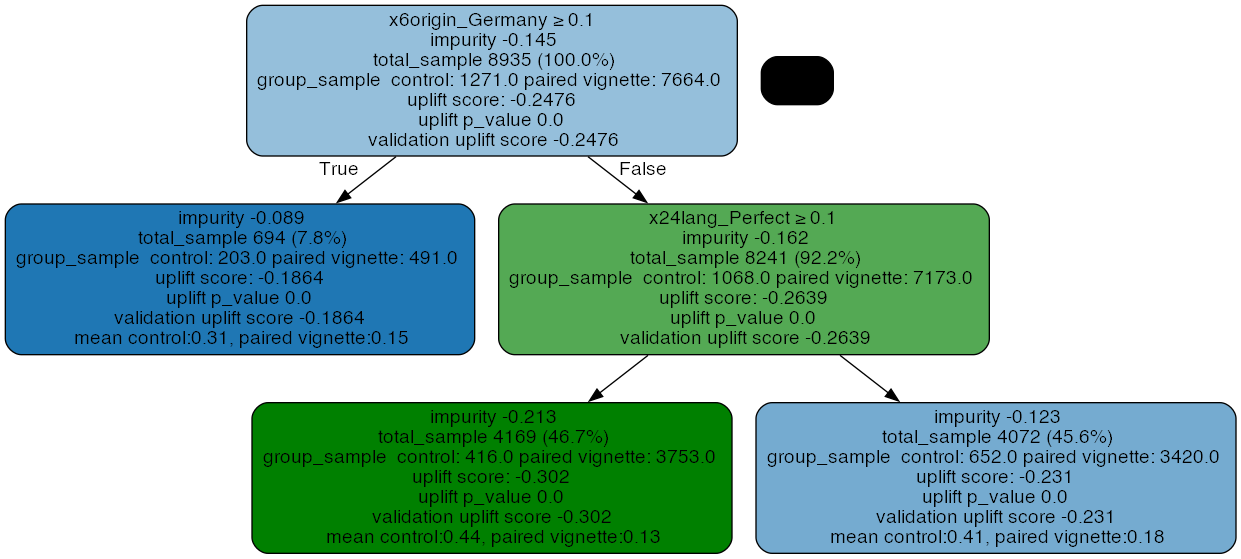

In [31]:
graph = uplift_tree_plot(uplift_tree_all.fitted_uplift_tree,x_names)
Image(graph.create_png())

#### 2.1.2 Uplift Tree Classifier-Train Test Split

In [32]:
# Split data to training and testing samples for model validation (next section)
df_train, df_test = train_test_split(swiss_votes, test_size=0.2, random_state=111)

In [33]:
# Train uplift tree
uplift__tree_train = UpliftTreeClassifier(max_depth = 3, min_samples_leaf = 200, control_name='control')

uplift__tree_train.fit(df_train[x_names].values,
                 treatment=df_train['treatment'].values,
                 y=df_train['y_factual'].values)

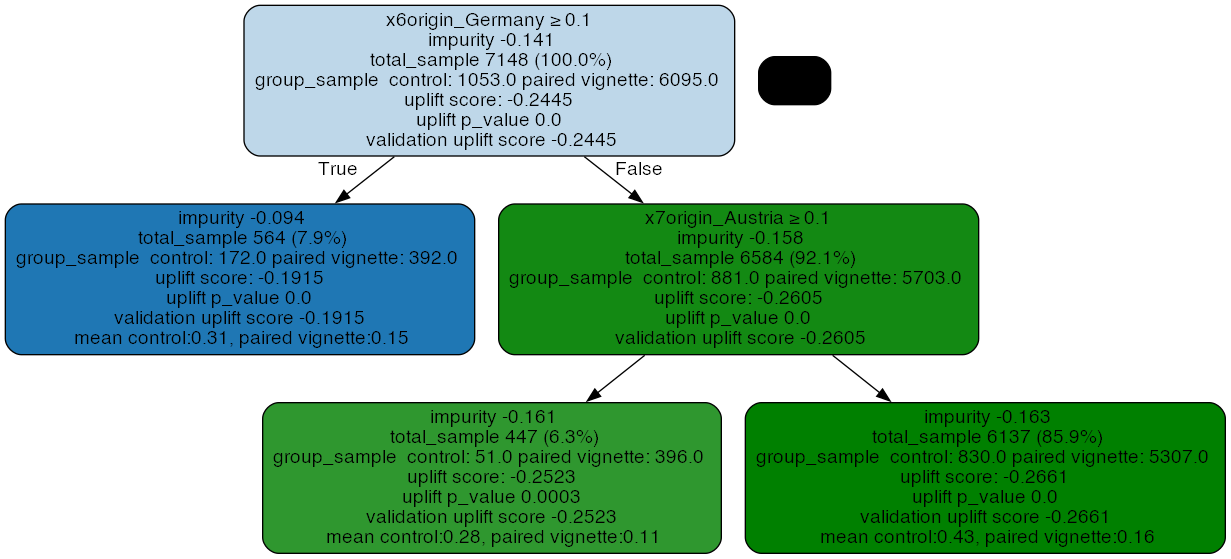

In [34]:
graph = uplift_tree_plot(uplift__tree_train.fitted_uplift_tree,x_names)
Image(graph.create_png())

### 2.2 Uplift Random Forest Classifier

#### 2.2.1 Uplift Random Forest Classifier - All Data

In [35]:
from causalml.inference.tree import UpliftTreeClassifier, UpliftRandomForestClassifier

In [36]:
# Train uplift tree
#define the forest model
uplift_forest_model = UpliftRandomForestClassifier(n_estimators=5,
                                                   max_depth = 5,
                                                   min_samples_leaf = 200,
                                                   min_samples_treatment = 50,
                                                   n_reg = 100, 
                                                   evaluationFunction='KL',
                                                   control_name='control')

#fir the forest model
uplift_forest_model.fit(swiss_votes[x_names].values,
                 treatment=swiss_votes['treatment'].values,
                 y=swiss_votes['y_factual'].values)

In [37]:
# Specify a tree in the random forest (the index can be any integer from 0 to n_estimators-1)
uplift_tree = uplift_forest_model.uplift_forest[0]
# Print uplift tree as a string
result = uplift_tree_string(uplift_tree.fitted_uplift_tree, x_names)

x6origin_Germany >= 0.1?
yes -> [0.3174568753040165, 0.1440329218106996]
no  -> x17integ_Traditions >= 0.1?
		yes -> x4gender_male >= 0.1?
				yes -> [0.5114635298778485, 0.12849162011173185]
				no  -> [0.48141514948786124, 0.144]
		no  -> x11origin_Croatia >= 0.1?
				yes -> [0.4415166758000851, 0.24411134903640258]
				no  -> x1age >= 35.5?
						yes -> [0.41271592696194886, 0.1711509715994021]
						no  -> [0.40586857231063467, 0.12550425818018826]


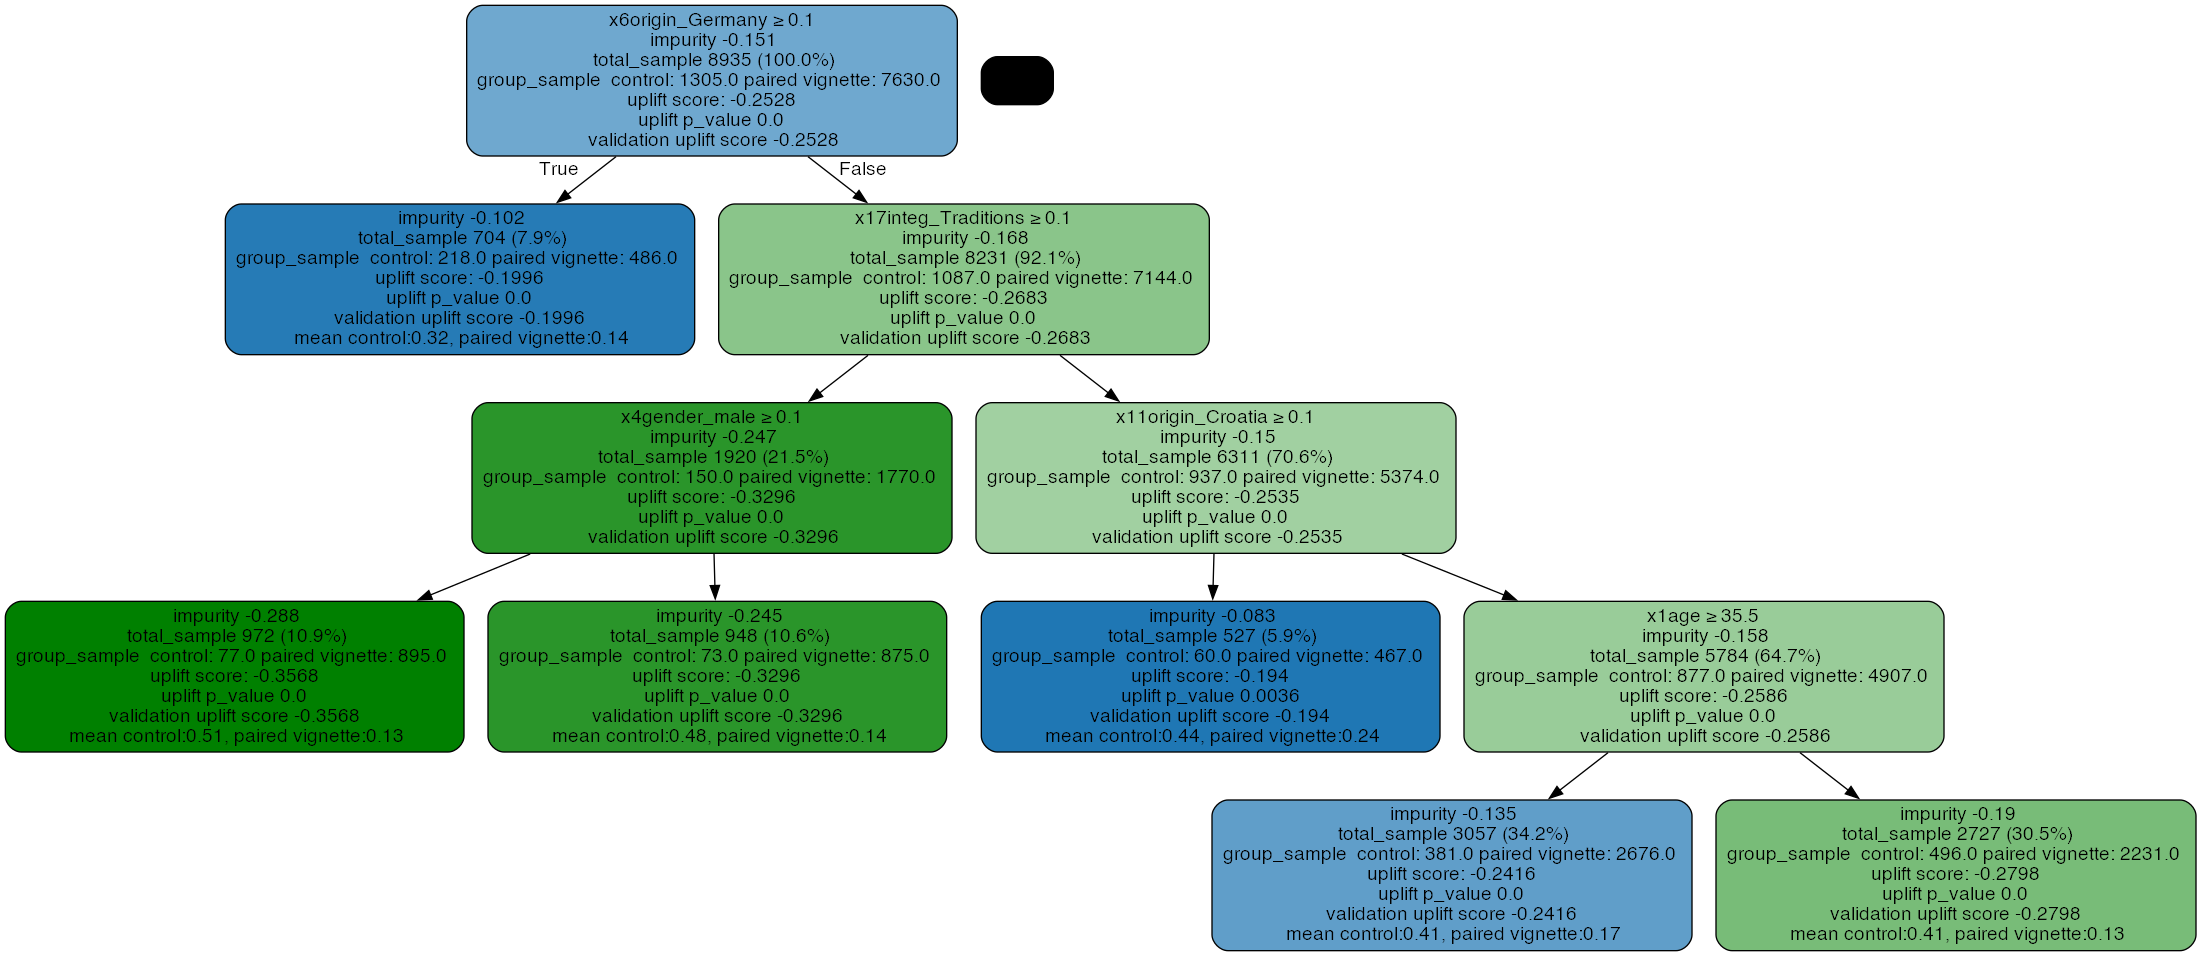

In [42]:
# Plot uplift tree
graph = uplift_tree_plot(uplift_tree.fitted_uplift_tree,x_names)
Image(graph.create_png())

#### 2.2.2 Uplift Random Forest Classifier - Train Test Split

In [38]:
# Split data to training and testing samples for model validation (next section)
df_train, df_test = train_test_split(swiss_votes, test_size=0.2, random_state=11)

In [39]:
uplift_forest_model = UpliftRandomForestClassifier(n_estimators=5,
                                                   max_depth = 5,
                                                   min_samples_leaf = 200,
                                                   min_samples_treatment = 50,
                                                   n_reg = 100, 
                                                   evaluationFunction='KL',
                                                   control_name='control')

#fir the forest model
uplift_forest_model.fit(df_train[x_names].values,
                 treatment=df_train['treatment'].values,
                 y=df_train['y_factual'].values)

##  <font color=#FF0000>3 - Plot Feature Importance</font>

### 3.1 Feature importance of Tree Model

<AxesSubplot: >

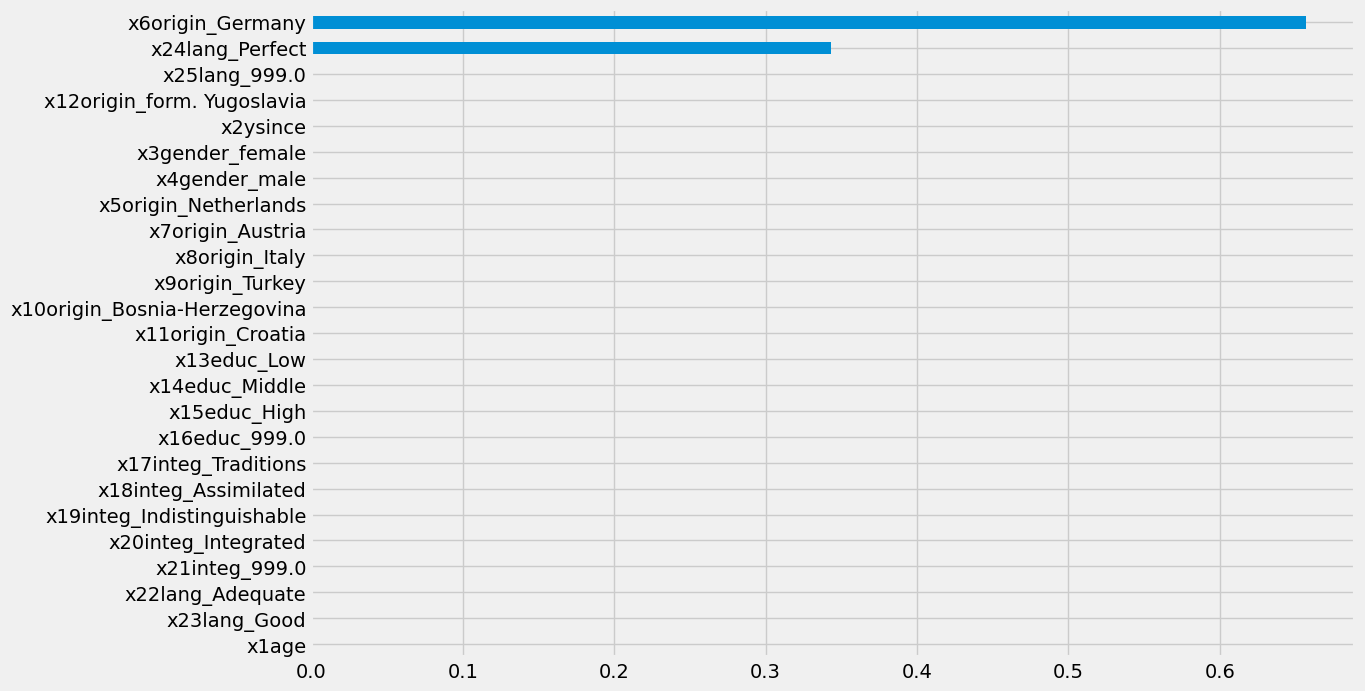

In [40]:
pd.Series(uplift_tree_all.feature_importances_, index=x_names).sort_values().plot(kind='barh', figsize=(12,8))

### 3.2 Feature importance of Random Forest Model

<AxesSubplot: >

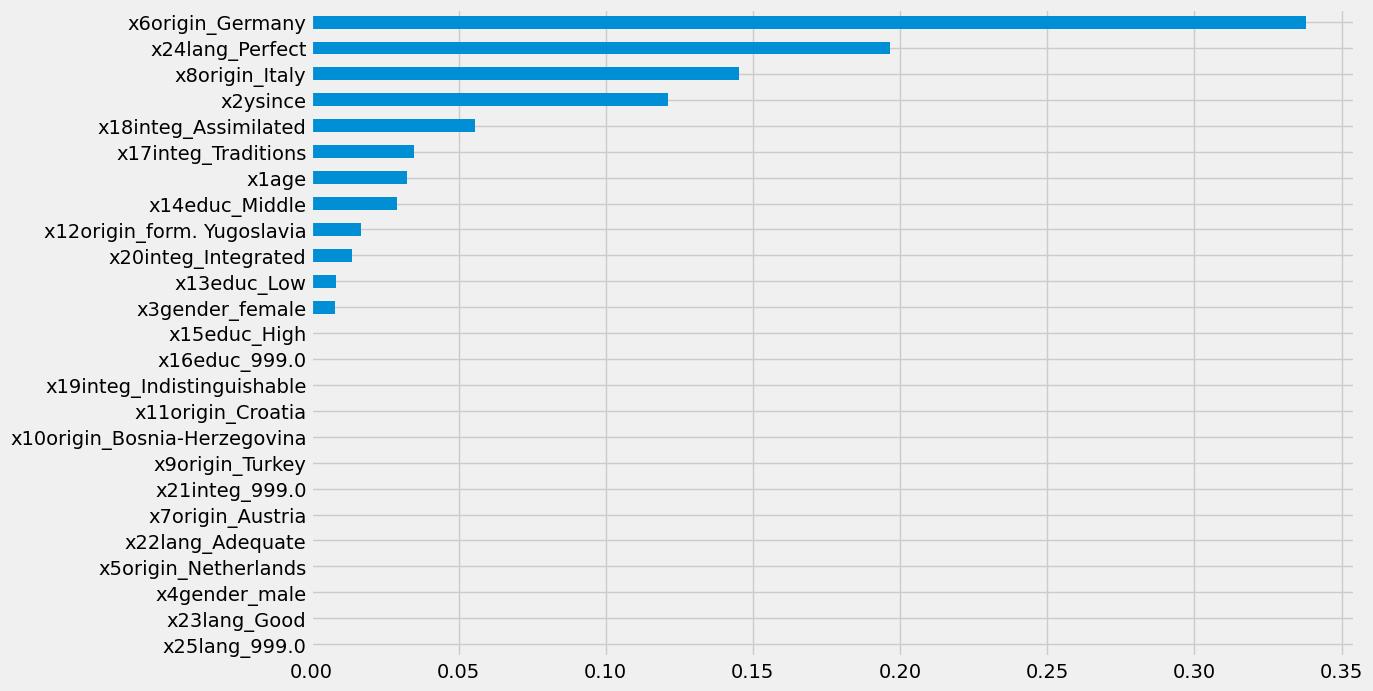

In [41]:
pd.Series(uplift_forest_model.feature_importances_, index=x_names).sort_values().plot(kind='barh', figsize=(12,8))

##  <font color=#FF0000>4 - Analysis</font>

## 4.1 Classification Model Description
The tree models describe several important data ponts. First, the impurity which is a measure of the value of the split criterion function (such as KL, Chi, or ED) evaluated at this current node. The lower this value the most sensitvie the criteria. Next, the total_sample is sample size in this node. Next, the group_sample is sample sizes by treatment groups. Following this we have the uplift score which is the treatment effect in this node. Next, the uplift p_value defines the p value of the treatment effect in this node. A low p value indicates a high degree of effect. Next the validation uplift score records represents the treatment effect of the testing data when the method fill() is used. This score can be used as a comparison to the training uplift score, to evaluate if the tree has an overfitting issue.
<br><br>

#### 4.2.1 Tree Classificaion Model Analysis

The tree model shows a few key insights. First most candidates in the sample tend to not have the Swiss citizen recoomendation. Out of all applicants, only about 20% of all applicants recived the reccomendation of swiss citizens. Most of the applicants who are of german origin are not accepted. Between the control and the treatment the german origin effect is more pronouced. In the treatment option the same german applicant is half as likely to be accepted or chosen then the control group. This subset of german origin represents only 8% of total studied population.The impurity score of -0.094 indicates that the selection criteria is quite stringent. Furthermore the uplift score of -0.1915 which indicates that the effect of the treatment effect is weak, however the pvalue of 0 indicates that this is a relavant split and grouping.
<br><br>
The remaining 92% of the population most likely to be reccomended for citizenship. This population is split into 86% and  6%. The 6% group are of Autstralian origin, and subset is less likely to be reccomended for citizenship that the remaining population. The uplift score of -0.25 indicates a stronger grouping and connections than other whic the p values of >0.005 indicates a relavance at the 95% confidence level

#### 4.2.2 Random Forest Classificaion Model Analysis

The forest model indicates that a similar tren with control vs the treatement. The treament mean acceptances were lower than any conrol group. In each condition the mean reccomendation score for the control group is twice the treatment option.Furthermore the model reveals there are several groups that have more likelyhood over others to be reccomended for swiss citizenship. The german origin groupin are less likely than others to be reccomended for citizenship with the same prediction strength as previously mentioned.
<br><br>
The applicats who indicate that they integrate following swiss traditions are more likely to be reccomended for swiss citzenship. The male applicats have a slghly higher application rate against women 51% vs 48% respectively. The uplift score is higher for the male applications (-0.36) indicating a higher relavance within the model while the low p values indicate a high degree of certanty.
<br><br>
Furthermore, the applicants from Croatia have a low likelyhood of being reccomended for citizenship. The numbers indcate a a similar level of relavance and certainty of the gernam origina applicants.
<br><br>
Lastly, applications who are above 35.5 years old have a higher likelyhood of reccomendation to be swiss citizens. Applicats over 35.5 years old have an uplift score is -0.28 indicating an acceptable level of relance with a low p value. Applicants under this key age have similar characteristics but are most likely to not be reccomended for citizenship

##  <font color=#FF0000>5 - Conclusion</font>

The data set examins the desire for immigrants with certain characteristics. Swiss citizens vote on the desire to have these people become citizens. Two expiramental setups examin the likelihood of voting 'yes' or 'no' on whether an applicant should become a citizen.
<br><br>
The comparative study is an ideal setup for a causl inference model. Specifically, usings tree and forest based models help detect hidden relationships via control and test condisions. In this case Swiss Voters accept immigrates at a much higher rate under control or non-comparative conditions. The vignette design of this expirament indicates that a comparative mindset with other immigrants reduces everyone overall chances for immigration.
<br><br>
The government can use the application format to modulate and design the survey to control up or down the overall desired number of immigrants and their respective 'quality'. The main factors that played roles in the control and treatment were whether or not the applicant was of gernamn origin and whether their language skills were not perfect. These two groups had the most success of becoming swiss.
<br><br>
The feature imporance plots back the decsion nodes. The random forest importance plot demonstrates other features that are just as important for determining the overall decsion for the applicatnt. Factors like Italian origin, age, age since  living in swizerland, their integration status, and education demonstrate relavant criteria for becoming swiss. Therefore random forest is helping to detect hidden features that require additional sesnitivity to detect.
<br> <br>
Therefore the swiss government can use the display of information to help determine the number of immigrants within their country. Using a format with 2 applicants on page page with information clearly displayed lowers the chances of becoming swiss versus one person per page with a block of text. However, ethically, this is a dangerous idea and immigration should instead rely on a process of naturalization and demonstration of desire to live in a place without any comparative judgment to other immigrats.